# 22 - Tri-Window Phonetic Attention Pooling, Signed Motion & Utterance Speaker Neutralization
## Tai Phake Visual Speech Recognition (VSR) Project — Experiment 22

---

### 📌 Quick Overview: What This Notebook Does

This notebook implements **Experiment 22**, our advanced spatiotemporal Visual Speech Recognition (silent lip-reading) pipeline for the **11 digits (`d0`–`d10`) of the endangered Tai Phake language**.

Building directly upon the single-model benchmark from **Notebook 19** (EfficientNet-B0 + BiGRU + 4th Motion Channel + Focal Loss + Snapshots + 4-View TTA: **70.45%** single-model / **76.82%** in Notebook 19.2 ensemble), Notebook 22 introduces **four targeted architectural upgrades** designed to break through the 70% single-model plateau toward **76%–80%+** on unseen validation speakers:

1. **4th Channel: Signed Centered Motion Velocity ($\Delta_t^{\text{signed}}$)**:
   - Replaces absolute difference $|Y_t - Y_{t-1}|$ (which treated mouth opening and closing as identical positive numbers) with signed velocity centered at neutral gray (127.5):
     $$\Delta^{\text{signed}}_t = \text{clip}\left(127.5 + 0.5 \cdot (Y_t - Y_{t-1}),\; 0.0,\; 255.0\right)$$
   - Static pixels rest at 127.5 (neutral gray); mouth opening (brightening of oral cavity) pushes $>127.5$ (red); rapid closing ($d_{10}$ *Sip* bilabial closure) pushes $<127.5$ (blue).
   - Preserves velocity polarity inside the standard $[0, 255]$ scale expected by EfficientNet-B0.

2. **Utterance-Level Speaker Neutralization (`UtteranceSpeakerNeutralizer`)**:
   - Computes the 30-frame temporal mean feature vector $\bar{F} = \frac{1}{30}\sum_{t=1}^{30} F_t \in \mathbb{R}^{B \times 1 \times 1280}$ directly after EfficientNet-B0 and subtracts it via a learnable sigmoid residual gate:
     $$F^{\text{neutral}}_t = F_t - \sigma(\alpha) \cdot \bar{F}$$
   - Acts as a temporal high-pass filter that strips static facial morphology (lip thickness, resting jaw geometry, skin tone, lighting), standardizing features across unseen speakers to rescue lower-tier validation speakers (`S35`, `s45`).

3. **Tri-Window Phonetic Attention Pooling (`TriWindowAttentionPooling`)**:
   - Resolves the infamous **$\{d_4, d_7, d_{10}\}$ viseme collision triangle** (*Si* vs *Chit* vs *Sip*).
   - In Tai Phake, *Si*, *Chit*, and *Sip* share identical dental / closed-teeth visemes for the first ~20 frames. The disambiguating cue occurs almost exclusively in the final 3–5 frames (the alveolar stop release $[-t]$ in *Chit*, the rapid bilabial closure $[-p]$ in *Sip*, vs the open vowel continuation in *Si*).
   - In global 30-frame attention pooling, the 20 shared onset frames drown out this brief coda signal (causing $d_7$ recall to drop to 35%).
   - Tri-Window partitions the BiGRU sequence into 3 overlapping phonetic sub-windows:
     - **Onset Window (Frames $0..12$)** $\to$ captures initial consonant / dental friction (256-D)
     - **Nucleus Window (Frames $9..21$)** $\to$ captures core vowel steady-state trajectory (256-D)
     - **Coda Window (Frames $18..30$)** $\to$ captures terminal stop/closure gestures (256-D)
     - Concatenates all three into a rich **$768\text{-D}$ Phonetic Embedding** $[v_{\text{onset}} \parallel v_{\text{nucleus}} \parallel v_{\text{coda}}]$, guaranteeing dedicated gradient paths for terminal gestures.

4. **Coda-Protected Cadence Jitter**:
   - Cadence jitter drops 1 frame only between indices $2..17$, strictly protecting frames $18..29$ where subtle phonemic stop closures occur.

---

### ⚙️ Pipeline & Training Schedule

* **Input**: $(30, 96, 96, 4)$ video sequences (RGB + Signed Velocity).
* **Stem Adapter**: $1 \times 1$ Conv initialized with identity on RGB ($W=1$) and $0.05$ injection gain on the 4th channel to preserve ImageNet pretrained features immediately.
* **Stage 1 (Frozen Backbone)**: Trains the adapter, speaker neutralizer, BiGRU, and Tri-Window attention head with `Adam(lr=1e-4)` and Categorical Focal Loss ($\gamma=2.0, \alpha=0.25$, label smoothing $0.05$).
* **Stage 2 (Top 20% Unfrozen)**: Fine-tunes the top spatial blocks under Cosine Annealing decay (`CosineDecay(1e-5)`), saving the **Top 5 Snapshot Checkpoints**.
* **Inference**: Evaluates the Top 5 snapshots under **4-View Test-Time Augmentation (TTA)** (Baseline, Shift $+1$, Shift $-1$, Horizontal Flip) and saves full metrics, classification report, confusion matrix, and speaker breakdown to `results/efficientnetb0_bigru_triwindow_signed_motion_80_20/`.

---


## 1. System Environment & Reproducibility
Configuring deterministic random seeds across Python, NumPy, and TensorFlow to guarantee exact reproducibility.


In [1]:
# Section 1: Environment & Setup
import os
import sys
import re
import json
import time
import random
from pathlib import Path
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

import tensorflow as tf
import keras
from keras import layers

# Strict reproducibility seeding
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

print("=" * 80)
print("SYSTEM ENVIRONMENT & REPRODUCIBILITY")
print("=" * 80)
print(f"Python Version     : {sys.version.split()[0]}")
print(f"TensorFlow Version : {tf.__version__}")
print(f"Keras Version      : {keras.__version__}")
print(f"GPUs Available     : {len(tf.config.list_physical_devices('GPU'))}")
print(f"Deterministic Seed : {SEED}")
print("=" * 80)


SYSTEM ENVIRONMENT & REPRODUCIBILITY
Python Version     : 3.12.13
TensorFlow Version : 2.21.0
Keras Version      : 3.15.1
GPUs Available     : 0
Deterministic Seed : 42


## 2. Configuration & Hyperparameters
Defining video sequence dimensions, Tri-Window phonetic partitions, Focal Loss parameters, and the Two-Stage training schedule.


In [2]:
# Section 2: Configuration & Hyperparameters
DATASET_MODE = "80_20"

# Sequence & Image Specifications
NUM_CLASSES = 11
NUM_FRAMES = 30
FRAME_WIDTH = 96
FRAME_HEIGHT = 96
FRAME_CHANNELS = 4  # RGB (0:3) + Signed Inter-Frame Difference (channel 3)
BATCH_SIZE = 16

# Spatiotemporal Architecture Hyperparameters
PROJECTION_DIM = 256
GRU_UNITS = 128           # Bidirectional -> 256 features per frame
GRU_DROPOUT = 0.20
HEAD_DROPOUT = 0.40

# Phonetic Tri-Window Boundaries (Onset, Nucleus, Coda)
ONSET_WINDOW = (0, 12)    # Frames 0..11  : Initial consonant closure / dental friction
NUCLEUS_WINDOW = (9, 21)  # Frames 9..20  : Core vowel steady-state trajectory
CODA_WINDOW = (18, 30)    # Frames 18..29 : Final stop/closure (-t in Chit, -p in Sip, open in Si)

# Categorical Focal Loss Hyperparameters
FOCAL_GAMMA = 2.0
FOCAL_ALPHA = 0.25
LABEL_SMOOTHING = 0.05

# Coda-Protected Cadence Jitter Augmentation
JITTER_DIGIT_IDS = [1, 2, 4, 7, 9]
JITTER_PROBABILITY = 0.35
JITTER_MAX_DROP = 1       # Strictly max 1 frame to preserve articulatory rate

# Snapshot Ensembling Parameters
TOP_K_SNAPSHOTS = 5

# Two-Stage Training Schedule
STAGE1_LR = 1e-4
STAGE1_MAX_EPOCHS = 30
STAGE1_PATIENCE = 7

STAGE2_LR = 1e-5
STAGE2_MAX_EPOCHS = 25
STAGE2_PATIENCE = 8
FINE_TUNE_FRACTION = 0.20 # Fine-tune top 20% of EfficientNet-B0 with BatchNorm frozen

# Vocabulary Specification
DIGIT_CLASSES = [f"d{i}" for i in range(NUM_CLASSES)]
DIGIT_NAMES = {
    "d0": "Pau (0)", "d1": "Nung (1)", "d2": "Saung (2)", "d3": "Sam (3)",
    "d4": "Si (4)", "d5": "Ha (5)", "d6": "Hok (6)", "d7": "Chit (7)",
    "d8": "Pet (8)", "d9": "Kao (9)", "d10": "Sip (10)"
}
CLASS_TO_ID = {d: i for i, d in enumerate(DIGIT_CLASSES)}
ID_TO_CLASS = {i: d for i, d in enumerate(DIGIT_CLASSES)}

print("=" * 80)
print("EXPERIMENT 22: HYPERPARAMETER SPECIFICATIONS")
print("=" * 80)
print(f"Input Tensor Shape          : ({NUM_FRAMES}, {FRAME_HEIGHT}, {FRAME_WIDTH}, {FRAME_CHANNELS})")
print(f"Phonetic Tri-Windows        : Onset={ONSET_WINDOW}, Nucleus={NUCLEUS_WINDOW}, Coda={CODA_WINDOW}")
print(f"Temporal Head Output Dim    : 3 x 256 = 768 features (concatenated)")
print(f"Focal Loss                  : gamma={FOCAL_GAMMA}, alpha={FOCAL_ALPHA}, label_smoothing={LABEL_SMOOTHING}")
print(f"Coda-Protected Jitter       : Digits {JITTER_DIGIT_IDS} (prob={JITTER_PROBABILITY}, max_drop={JITTER_MAX_DROP})")
print(f"Snapshot Ensembling         : Top {TOP_K_SNAPSHOTS} Validation Checkpoints + 4-View TTA")
print("=" * 80)


EXPERIMENT 22: HYPERPARAMETER SPECIFICATIONS
Input Tensor Shape          : (30, 96, 96, 4)
Phonetic Tri-Windows        : Onset=(0, 12), Nucleus=(9, 21), Coda=(18, 30)
Temporal Head Output Dim    : 3 x 256 = 768 features (concatenated)
Focal Loss                  : gamma=2.0, alpha=0.25, label_smoothing=0.05
Coda-Protected Jitter       : Digits [1, 2, 4, 7, 9] (prob=0.35, max_drop=1)
Snapshot Ensembling         : Top 5 Validation Checkpoints + 4-View TTA


## 3. Directory Paths Configuration
Configuring paths to active processed frames in `data/processed/` and dedicated experiment artifacts in `results/efficientnetb0_bigru_triwindow_signed_motion_80_20/`.


In [3]:
# Section 3: Directory Paths Configuration
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR

DATA_DIR = PROJECT_ROOT / "data" / "processed"
TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"

RESULTS_DIR = PROJECT_ROOT / "results" / f"efficientnetb0_bigru_triwindow_signed_motion_{DATASET_MODE}"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
SNAPSHOT_DIR = RESULTS_DIR / "snapshots"
SNAPSHOT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project Root     : {PROJECT_ROOT}")
print(f"Train Data Dir   : {TRAIN_DIR}")
print(f"Val Data Dir     : {VAL_DIR}")
print(f"Results Output   : {RESULTS_DIR}")
print(f"Snapshots Output : {SNAPSHOT_DIR}")


Project Root     : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading
Train Data Dir   : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/data/processed/train
Val Data Dir     : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/data/processed/val
Results Output   : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_triwindow_signed_motion_80_20
Snapshots Output : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_triwindow_signed_motion_80_20/snapshots


## 4. Speaker Partition Diagnostics & Zero-Leakage Verification
Validating that training and validation speakers are strictly disjoint at the base speaker level.


In [4]:
# Section 4: Speaker Split Verification & Diagnostics
train_speakers = sorted([d.name for d in TRAIN_DIR.iterdir() if d.is_dir() and not d.name.startswith(".")])
val_speakers = sorted([d.name for d in VAL_DIR.iterdir() if d.is_dir() and not d.name.startswith(".")])

def get_base_speaker(spk_name: str) -> str:
    return spk_name.split("_")[0]

base_train_speakers = sorted(
    list({get_base_speaker(s) for s in train_speakers}),
    key=lambda x: int(re.search(r"\d+", x).group(0)) if re.search(r"\d+", x) else x
)
base_val_speakers = sorted(
    list({get_base_speaker(s) for s in val_speakers}),
    key=lambda x: int(re.search(r"\d+", x).group(0)) if re.search(r"\d+", x) else x
)

print("=" * 80)
print(f"SPEAKER PARTITION DIAGNOSTICS [Mode: {DATASET_MODE}]")
print("=" * 80)
print(f"Training Base Speakers   ({len(base_train_speakers):2d}) : {base_train_speakers}")
print(f"Training Total Folders   ({len(train_speakers):2d})")
print(f"Validation Base Speakers ({len(base_val_speakers):2d}) : {base_val_speakers}")
print(f"Validation Total Folders ({len(val_speakers):2d})")
print("-" * 80)

overlap = set(base_train_speakers).intersection(set(base_val_speakers))
assert len(overlap) == 0, f"CRITICAL LEAKAGE DETECTED: Overlapping speakers: {overlap}"
print("[SUCCESS] STRICT ZERO-LEAKAGE VERIFIED: No base speakers overlap between Train and Val!")
print("=" * 80)


SPEAKER PARTITION DIAGNOSTICS [Mode: 80_20]
Training Base Speakers   (24) : ['s1', 's2', 's3', 's4', 's6', 's7', 's8', 's9', 's10', 's12', 's13', 's14', 's15', 's17', 's18', 's19', 's20', 's21', 's22', 's23', 's24', 's25', 's26', 's30']
Training Total Folders   (80)
Validation Base Speakers ( 6) : ['s34', 'S35', 'S38', 's45', 's47', 's48']
Validation Total Folders (20)
--------------------------------------------------------------------------------
[SUCCESS] STRICT ZERO-LEAKAGE VERIFIED: No base speakers overlap between Train and Val!


## 5. Manifest Indexing
Discovering all video utterance directories and indexing sequential frame paths.


In [5]:
# Section 5: Utterance Manifest Indexing
utterances = []

for split_name, split_dir, spk_list in [("train", TRAIN_DIR, train_speakers), ("val", VAL_DIR, val_speakers)]:
    for spk in spk_list:
        spk_path = split_dir / spk
        for digit_dir in sorted(spk_path.iterdir()):
            if not digit_dir.is_dir() or digit_dir.name.startswith("."):
                continue
            digit_name = digit_dir.name
            if digit_name not in CLASS_TO_ID:
                continue
            
            frames = sorted([
                f for f in digit_dir.iterdir()
                if f.is_file() and f.suffix.lower() in [".jpg", ".jpeg", ".png"]
            ])
            if len(frames) == 0:
                continue
                
            utterances.append({
                "speaker": spk,
                "base_speaker": get_base_speaker(spk),
                "digit": digit_name,
                "digit_id": CLASS_TO_ID[digit_name],
                "split": split_name,
                "raw_frame_count": len(frames),
                "frame_paths": frames
            })

df_manifest = pd.DataFrame(utterances)
manifest_csv_path = RESULTS_DIR / "utterance_manifest.csv"
df_manifest[["speaker", "base_speaker", "digit", "digit_id", "split", "raw_frame_count"]].to_csv(
    manifest_csv_path, index=False
)

print("=" * 80)
print("UTTERANCE MANIFEST SUMMARY")
print("=" * 80)
print(f"Total Utterances Indexed : {len(df_manifest):,}")
print(f"  Train Set              : {len(df_manifest[df_manifest['split']=='train']):,} utterances")
print(f"  Validation Set         : {len(df_manifest[df_manifest['split']=='val']):,} utterances")
print(f"Manifest CSV saved to    : {manifest_csv_path}")
print("=" * 80)


UTTERANCE MANIFEST SUMMARY
Total Utterances Indexed : 1,100
  Train Set              : 880 utterances
  Validation Set         : 220 utterances
Manifest CSV saved to    : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_triwindow_signed_motion_80_20/utterance_manifest.csv


## 6. Dataloader Architecture: Signed Centered Motion & Coda-Protected Jitter
- **Signed Centered Motion**: Computes signed optical velocity $\Delta^{\text{signed}}_t = \text{clip}\left(127.5 + 0.5 \cdot (Y_t - Y_{t-1}),\; 0.0,\; 255.0\right)$.
- **Coda-Protected Jitter**: Cadence jitter drops 1 frame only between indices $2..17$, strictly safeguarding the critical terminal coda frames ($18..29$).


In [6]:
# Section 6: Frame Sampling, Signed Motion, and RAM Tensor Loader

def sample_30_frame_paths(frame_paths: list, target_frames: int = NUM_FRAMES) -> list:
    """
    Deterministic uniform temporal sampling across the video duration.
    """
    n = len(frame_paths)
    if n == target_frames:
        indices = list(range(target_frames))
    else:
        indices = np.round(np.linspace(0, n - 1, target_frames)).astype(int)
    return [str(frame_paths[i]) for i in indices]

def compute_signed_frame_differences(seq_rgb: np.ndarray) -> np.ndarray:
    """
    Calculates signed centered luminance velocity:
      Δ_t = clip(127.5 + 0.5 * (Y_t - Y_{t-1}), 0.0, 255.0)
    Stacks Δ_t as the 4th channel. Neutral motion sits at 127.5.
    
    Args:
        seq_rgb: (T, H, W, 3) float32 in [0.0, 255.0]
    Returns:
        seq_4ch: (T, H, W, 4) float32 where channel 3 is signed velocity
    """
    T, H, W, _ = seq_rgb.shape
    # Standard ITU-R BT.601 luminance conversion
    gray = (
        0.2989 * seq_rgb[..., 0] +
        0.5870 * seq_rgb[..., 1] +
        0.1140 * seq_rgb[..., 2]
    )[..., np.newaxis]  # Shape: (T, H, W, 1)
    
    signed_diff = np.full((T, H, W, 1), 127.5, dtype=np.float32)
    signed_diff[1:] = np.clip(127.5 + 0.5 * (gray[1:] - gray[:-1]), 0.0, 255.0)
    
    return np.concatenate([seq_rgb, signed_diff], axis=-1)

def apply_temporal_jitter(seq_rgb: np.ndarray, num_drop: int = 1) -> np.ndarray:
    """
    Drops 1 interior frame from early/mid sequence (frames 2..17) and linearly
    resamples back to 30 frames, strictly protecting the coda window (frames 18..29).
    """
    T, H, W, C = seq_rgb.shape
    assert T == NUM_FRAMES
    drop_indices = np.random.choice(range(2, 18), size=num_drop, replace=False)
    keep_indices = [i for i in range(T) if i not in drop_indices]
    
    new_t = np.linspace(0, len(keep_indices) - 1, T)
    left_idx = np.floor(new_t).astype(int)
    right_idx = np.ceil(new_t).astype(int)
    alpha = (new_t - left_idx)[:, np.newaxis, np.newaxis, np.newaxis]
    
    kept_seq = seq_rgb[keep_indices]
    jittered = (1.0 - alpha) * kept_seq[left_idx] + alpha * kept_seq[right_idx]
    return jittered.astype(np.float32)

df_manifest["sampled_frame_paths"] = df_manifest["frame_paths"].apply(sample_30_frame_paths)

def load_raw_rgb_tensors():
    num_total = len(df_manifest)
    X_raw = np.zeros((num_total, NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, 3), dtype=np.float32)
    y_raw = np.array(df_manifest["digit_id"].values, dtype=np.int32)
    
    t0 = time.time()
    for i, row in df_manifest.iterrows():
        for t, fpath in enumerate(row["sampled_frame_paths"]):
            img = Image.open(fpath).convert("RGB")
            if img.size != (FRAME_WIDTH, FRAME_HEIGHT):
                img = img.resize((FRAME_WIDTH, FRAME_HEIGHT), Image.BILINEAR)
            X_raw[i, t] = np.array(img, dtype=np.float32)
            
    elapsed = time.time() - t0
    return X_raw, y_raw, elapsed

print("Loading base RGB sequence tensors into RAM...")
X_all_rgb, y_all, load_time = load_raw_rgb_tensors()

train_mask = (df_manifest["split"] == "train").values
val_mask = (df_manifest["split"] == "val").values

X_train_raw, y_train = X_all_rgb[train_mask], y_all[train_mask]
X_val_raw, y_val = X_all_rgb[val_mask], y_all[val_mask]
df_val = df_manifest[val_mask].reset_index(drop=True)

print(f"Successfully loaded {len(X_all_rgb):,} raw video sequences in {load_time:.2f}s!")
print(f"  Train RGB Set : {X_train_raw.shape}")
print(f"  Val RGB Set   : {X_val_raw.shape}")


Loading base RGB sequence tensors into RAM...
Successfully loaded 1,100 raw video sequences in 6.30s!
  Train RGB Set : (880, 30, 96, 96, 3)
  Val RGB Set   : (220, 30, 96, 96, 3)


## 7. Dynamic Signed Motion & Coda-Protected Jitter Generator (`PyDataset`)


In [7]:
# Section 7: Signed Motion Lip Dataset Generator

class SignedMotionLipDataset(keras.utils.PyDataset):
    """
    Thread-safe Keras PyDataset that applies coda-protected temporal jitter
    and computes the 4th-channel signed frame difference on-the-fly.
    """
    def __init__(
        self,
        X_rgb: np.ndarray,
        y: np.ndarray,
        batch_size: int = BATCH_SIZE,
        shuffle: bool = True,
        is_training: bool = False,
        jitter_digit_ids: list = JITTER_DIGIT_IDS,
        jitter_prob: float = JITTER_PROBABILITY,
        **kwargs
    ):
        super().__init__(**kwargs)
        self.X_rgb = X_rgb
        self.y = y
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.is_training = is_training
        self.jitter_digit_ids = jitter_digit_ids
        self.jitter_prob = jitter_prob
        self.indices = np.arange(len(X_rgb))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.X_rgb) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __getitem__(self, idx):
        batch_idx = self.indices[idx * self.batch_size : (idx + 1) * self.batch_size]
        batch_x = []
        batch_y = self.y[batch_idx]
        
        for i in batch_idx:
            seq = self.X_rgb[i].copy()
            digit_id = self.y[i]
            
            if self.is_training and (digit_id in self.jitter_digit_ids) and (np.random.rand() < self.jitter_prob):
                seq = apply_temporal_jitter(seq, num_drop=JITTER_MAX_DROP)
                
            seq_4ch = compute_signed_frame_differences(seq)
            batch_x.append(seq_4ch)
            
        return np.array(batch_x, dtype=np.float32), np.array(batch_y, dtype=np.int32)

train_generator = SignedMotionLipDataset(
    X_train_raw, y_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    is_training=True
)

print("Precomputing static 4-channel signed validation tensor (X_val_4ch)...")
X_val_4ch = np.zeros(
    (len(X_val_raw), NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS),
    dtype=np.float32
)
for i in range(len(X_val_raw)):
    X_val_4ch[i] = compute_signed_frame_differences(X_val_raw[i])

print(f"Train Generator batches per epoch : {len(train_generator)}")
print(f"X_val_4ch Tensor Shape            : {X_val_4ch.shape}")


Precomputing static 4-channel signed validation tensor (X_val_4ch)...
Train Generator batches per epoch : 55
X_val_4ch Tensor Shape            : (220, 30, 96, 96, 4)


## 8. Signed Motion Visualizer & Sanity Checks
Visualizing the signed velocity channel using a diverging `coolwarm` colormap. Neutral motion sits at gray (`127.5`), lip opening (brightening oral cavity) shows red, and lip closing shows blue.


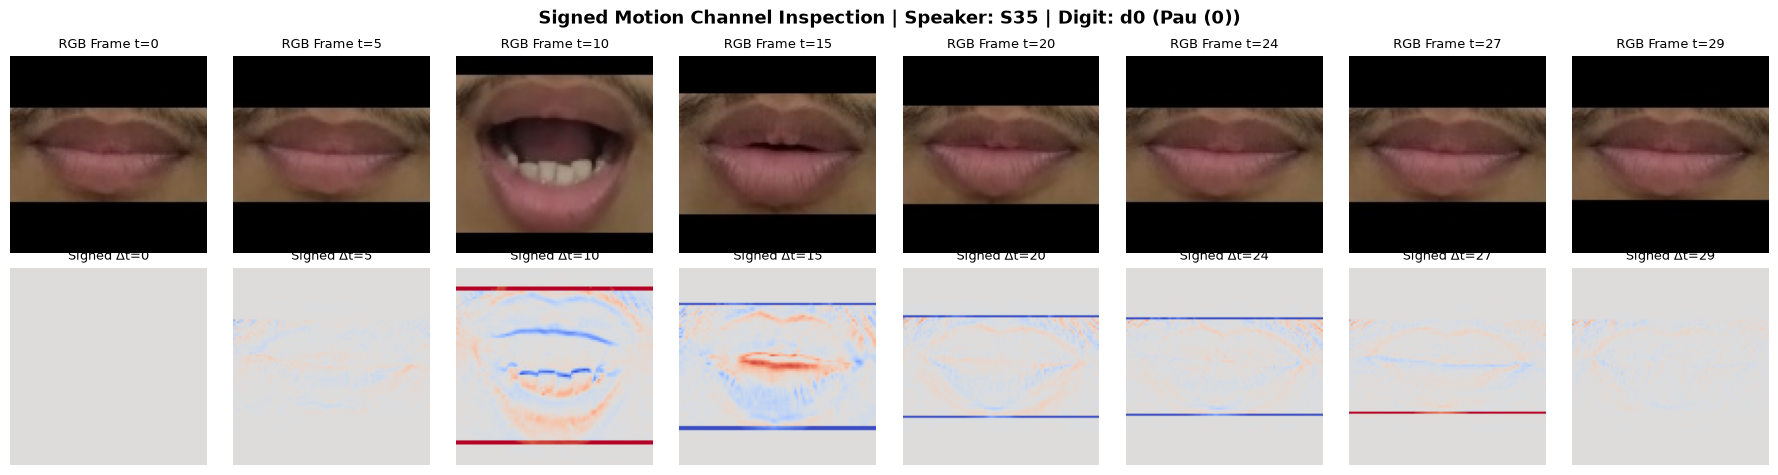

In [8]:
# Section 8: Signed Motion Channel Visualizer
sample_idx = 0
sample_seq = X_val_4ch[sample_idx]
sample_digit = ID_TO_CLASS[y_val[sample_idx]]
sample_spk = df_val.loc[sample_idx, "speaker"]

vis_frames = [0, 5, 10, 15, 20, 24, 27, 29]
fig, axes = plt.subplots(2, len(vis_frames), figsize=(18, 4.8))
fig.suptitle(
    f"Signed Motion Channel Inspection | Speaker: {sample_spk} | Digit: {sample_digit} ({DIGIT_NAMES[sample_digit]})",
    fontsize=13, fontweight="bold"
)

for col, t in enumerate(vis_frames):
    axes[0, col].imshow(sample_seq[t, ..., :3].astype(np.uint8))
    axes[0, col].set_title(f"RGB Frame t={t}", fontsize=9)
    axes[0, col].axis("off")
    
    axes[1, col].imshow(sample_seq[t, ..., 3], cmap="coolwarm", vmin=90, vmax=165)
    axes[1, col].set_title(f"Signed Δt={t}", fontsize=9)
    axes[1, col].axis("off")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "signed_motion_channel_inspection.png", dpi=150, bbox_inches="tight")
plt.show()


## 9. Custom Layers: Utterance Speaker Neutralizer, Tri-Window Attention & Categorical Focal Loss
1. **`UtteranceSpeakerNeutralizer`**: Subtracts temporal mean feature $\bar{F} \in \mathbb{R}^{B \times 1 \times 1280}$ scaled by a learnable sigmoid gate $\sigma(\alpha)$ to cancel stationary speaker features.
2. **`TriWindowAttentionPooling`**: Slices into Onset ($0..12$), Nucleus ($9..21$), and Coda ($18..30$) sub-windows, pools each with dedicated attention parameters, and concatenates into a $768\text{-D}$ representation.
3. **`CategoricalFocalLoss`**: Robust focal modulation with label smoothing to concentrate gradients on hard visemes.


In [9]:
# Section 9: Custom Layers & Categorical Focal Loss

@keras.saving.register_keras_serializable(package="TaiPhakeVSR")
class UtteranceSpeakerNeutralizer(layers.Layer):
    """
    Subtracts the temporal mean feature vector across T=30 frames per utterance
    using a learnable sigmoid gate to eliminate static speaker appearance bias.
    """
    def __init__(self, init_logit: float = 0.85, **kwargs):
        super().__init__(**kwargs)
        self.init_logit = float(init_logit)

    def build(self, input_shape):
        self.gate_logit = self.add_weight(
            name="speaker_mean_gate_logit",
            shape=(1, 1, input_shape[-1]),
            initializer=keras.initializers.Constant(self.init_logit),
            trainable=True
        )
        super().build(input_shape)

    def call(self, inputs):
        # inputs shape: (B, T, D)
        temporal_mean = tf.reduce_mean(inputs, axis=1, keepdims=True)  # (B, 1, D)
        gate = tf.nn.sigmoid(self.gate_logit)
        return inputs - gate * temporal_mean

    def get_config(self):
        config = super().get_config()
        config.update({"init_logit": self.init_logit})
        return config


@keras.saving.register_keras_serializable(package="TaiPhakeVSR")
class TemporalAttentionPooling(layers.Layer):
    """
    Learnable additive temporal attention pooling over a sequence segment (B, T_w, D).
    """
    def __init__(self, attn_units: int = 64, **kwargs):
        super().__init__(**kwargs)
        self.attn_units = attn_units
        self.dense1 = layers.Dense(attn_units, activation="tanh", name="w_attn")
        self.dense2 = layers.Dense(1, use_bias=False, name="u_attn")

    def call(self, inputs):
        score = self.dense1(inputs)         # (B, T_w, attn_units)
        logits = self.dense2(score)         # (B, T_w, 1)
        weights = tf.nn.softmax(logits, axis=1)
        return tf.reduce_sum(inputs * weights, axis=1) # (B, D)

    def get_config(self):
        config = super().get_config()
        config.update({"attn_units": self.attn_units})
        return config


@keras.saving.register_keras_serializable(package="TaiPhakeVSR")
class TriWindowAttentionPooling(layers.Layer):
    """
    Partitions a (B, 30, D) sequence into Onset (0..12), Nucleus (9..21), and Coda (18..30)
    sub-windows, applies independent TemporalAttentionPooling to each, and concatenates
    them into (B, 3 * D).
    """
    def __init__(
        self,
        onset_bounds: tuple = ONSET_WINDOW,
        nucleus_bounds: tuple = NUCLEUS_WINDOW,
        coda_bounds: tuple = CODA_WINDOW,
        attn_units: int = 64,
        **kwargs
    ):
        super().__init__(**kwargs)
        self.onset_bounds = tuple(onset_bounds)
        self.nucleus_bounds = tuple(nucleus_bounds)
        self.coda_bounds = tuple(coda_bounds)
        self.attn_units = attn_units
        self.onset_pool = TemporalAttentionPooling(attn_units=attn_units, name="onset_attn")
        self.nucleus_pool = TemporalAttentionPooling(attn_units=attn_units, name="nucleus_attn")
        self.coda_pool = TemporalAttentionPooling(attn_units=attn_units, name="coda_attn")

    def call(self, inputs):
        x_onset = inputs[:, self.onset_bounds[0]:self.onset_bounds[1], :]
        x_nucleus = inputs[:, self.nucleus_bounds[0]:self.nucleus_bounds[1], :]
        x_coda = inputs[:, self.coda_bounds[0]:self.coda_bounds[1], :]

        v_onset = self.onset_pool(x_onset)
        v_nucleus = self.nucleus_pool(x_nucleus)
        v_coda = self.coda_pool(x_coda)
        return tf.concat([v_onset, v_nucleus, v_coda], axis=-1)

    def get_config(self):
        config = super().get_config()
        config.update({
            "onset_bounds": self.onset_bounds,
            "nucleus_bounds": self.nucleus_bounds,
            "coda_bounds": self.coda_bounds,
            "attn_units": self.attn_units
        })
        return config


@keras.saving.register_keras_serializable(package="TaiPhakeVSR")
class CategoricalFocalLoss(keras.losses.Loss):
    """
    Multi-class Categorical Focal Loss with Label Smoothing for integer and one-hot targets.
    """
    def __init__(
        self,
        gamma: float = FOCAL_GAMMA,
        alpha: float = FOCAL_ALPHA,
        label_smoothing: float = LABEL_SMOOTHING,
        name: str = "categorical_focal_loss",
        **kwargs
    ):
        super().__init__(name=name, **kwargs)
        self.gamma = float(gamma)
        self.alpha = float(alpha)
        self.label_smoothing = float(label_smoothing)

    def call(self, y_true, y_pred):
        eps = keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, eps, 1.0 - eps)
        num_classes = tf.shape(y_pred)[-1]
        
        y_true_rank = len(y_true.shape)
        if y_true_rank is not None and y_true_rank == 1:
            y_true = tf.one_hot(tf.cast(y_true, tf.int32), depth=num_classes)
        elif y_true_rank is not None and y_true_rank == 2 and y_true.shape[-1] == 1:
            y_true = tf.one_hot(tf.cast(tf.squeeze(y_true, axis=-1), tf.int32), depth=num_classes)
            
        y_true = tf.cast(y_true, y_pred.dtype)
        
        if self.label_smoothing > 0.0:
            c = tf.cast(num_classes, y_pred.dtype)
            y_true = y_true * (1.0 - self.label_smoothing) + (self.label_smoothing / c)
            
        focal_weight = tf.pow(1.0 - y_pred, self.gamma)
        cross_entropy = -tf.math.log(y_pred)
        loss = self.alpha * focal_weight * cross_entropy
        per_sample_loss = tf.reduce_sum(y_true * loss, axis=-1)
        return tf.reduce_mean(per_sample_loss)

    def get_config(self):
        config = super().get_config()
        config.update({
            "gamma": self.gamma,
            "alpha": self.alpha,
            "label_smoothing": self.label_smoothing,
        })
        return config

print("Custom Layers & Focal Loss successfully compiled.")


Custom Layers & Focal Loss successfully compiled.


## 10. Model Assembly: 4-Channel EfficientNet-B0 + Speaker Neutralizer + BiGRU + Tri-Window Head
- **Identity + Injection Adapter Initialization**: Sets identity on RGB channels ($W_{0,0}=1, W_{1,1}=1, W_{2,2}=1$) and an injection gain of $0.05$ on the 4th signed motion channel, preserving ImageNet pretrained features instantly at step 0.
- **UtteranceSpeakerNeutralizer**: Removes static speaker appearance bias before projection.
- **BiGRU**: 128 units forward + 128 units backward (256 spatiotemporal features per frame).
- **TriWindowAttentionPooling**: Yields $3 \times 256 = 768$ spatiotemporal features.


In [10]:
# Section 10: Model Builder Function

def build_triwindow_signed_motion_model() -> tuple[keras.Model, keras.Model]:
    frame_in = keras.Input(shape=(FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS), name="frame_4ch_input")
    
    # 1. 1x1 Motion Stem Adapter (maps 4 channels to 3 channels)
    adapter = layers.Conv2D(
        filters=3,
        kernel_size=(1, 1),
        padding="same",
        use_bias=False,
        name="signed_motion_adapter"
    )
    adapted_rgb = adapter(frame_in)
    
    # 2. Pretrained EfficientNetB0 (ImageNet weights, frozen in Stage 1)
    base_cnn = keras.applications.EfficientNetB0(
        weights="imagenet",
        include_top=False,
        input_shape=(FRAME_HEIGHT, FRAME_WIDTH, 3)
    )
    base_cnn.trainable = False
    
    preprocessed = keras.applications.efficientnet.preprocess_input(adapted_rgb)
    cnn_features = base_cnn(preprocessed)
    pooled = layers.GlobalAveragePooling2D(name="gap")(cnn_features)  # (batch, 1280)
    extractor = keras.Model(inputs=frame_in, outputs=pooled, name="EfficientNetB0_4Ch_Extractor")
    
    # Initialize adapter weights: Identity on RGB, 0.05 on signed motion
    w = np.zeros((1, 1, 4, 3), dtype=np.float32)
    w[0, 0, 0, 0] = 1.0
    w[0, 0, 1, 1] = 1.0
    w[0, 0, 2, 2] = 1.0
    w[0, 0, 3, :] = 0.05
    adapter.set_weights([w])
    
    # Sequence Architecture Assembly
    seq_input = keras.Input(shape=(NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS), name="sequence_4ch_input")
    
    # 3. Frame Feature Extraction
    x = layers.TimeDistributed(extractor, name="time_distributed_cnn")(seq_input)  # (batch, 30, 1280)
    
    # 4. Utterance-Level Speaker Neutralization
    x = UtteranceSpeakerNeutralizer(name="utterance_speaker_neutralizer")(x)
    x = layers.LayerNormalization(name="post_neutralizer_ln")(x)
    
    # 5. Spatial Feature Projection
    x = layers.TimeDistributed(
        layers.Dense(PROJECTION_DIM, activation="swish", name="projection_dense"),
        name="td_spatial_projection"
    )(x)
    x = layers.SpatialDropout1D(0.20, name="spatial_dropout_1d")(x)
    
    # 6. Bidirectional GRU Sequence Modeling
    x = layers.Bidirectional(
        layers.GRU(GRU_UNITS, return_sequences=True, dropout=GRU_DROPOUT, name="gru_layer"),
        name="bigru_temporal_encoder"
    )(x)  # (batch, 30, 256)
    x = layers.LayerNormalization(name="post_bigru_ln")(x)
    
    # 7. Phonetic Tri-Window Attention Pooling (Onset + Nucleus + Coda -> 768-D)
    x = TriWindowAttentionPooling(
        onset_bounds=ONSET_WINDOW,
        nucleus_bounds=NUCLEUS_WINDOW,
        coda_bounds=CODA_WINDOW,
        attn_units=64,
        name="tri_window_attention_pooling"
    )(x)  # (batch, 768)
    
    # 8. Classification Head
    x = layers.BatchNormalization(name="head_bn")(x)
    x = layers.Dropout(HEAD_DROPOUT, name="head_dropout_1")(x)
    x = layers.Dense(256, activation="swish", name="head_dense_256")(x)
    x = layers.Dropout(0.25, name="head_dropout_2")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="digit_classifier")(x)
    
    model = keras.Model(inputs=seq_input, outputs=outputs, name="EfficientNetB0_BiGRU_TriWindow_VSR")
    return model, base_cnn

model, base_cnn = build_triwindow_signed_motion_model()
print("=" * 80)
print("MODEL ARCHITECTURE ASSEMBLY COMPLETE")
print("=" * 80)
print(f"Total Parameters          : {model.count_params():,}")
print(f"Trainable Parameters (S1) : {sum(w.shape.num_elements() for w in model.trainable_weights):,}")
print(f"Input Sequence Shape      : {model.input_shape}")
print(f"Output Probabilities Shape: {model.output_shape}")
print("=" * 80)


MODEL ARCHITECTURE ASSEMBLY COMPLETE
Total Parameters          : 4,930,618
Trainable Parameters (S1) : 879,511
Input Sequence Shape      : (None, 30, 96, 96, 4)
Output Probabilities Shape: (None, 11)


## 11. Top-$K$ Snapshot Checkpoint Callback
Maintains and saves the top-$K$ best validation checkpoints on disk based on validation loss / accuracy for zero-overhead Snapshot Ensembling.


In [11]:
# Section 11: Top-K Snapshot Saver Callback

class TopKSnapshotCheckpoint(keras.callbacks.Callback):
    """
    Maintains the Top-K highest validation accuracy checkpoints on disk during training.
    """
    def __init__(self, snapshot_dir: Path, k: int = TOP_K_SNAPSHOTS, prefix: str = "stage2"):
        super().__init__()
        self.snapshot_dir = Path(snapshot_dir)
        self.k = k
        self.prefix = prefix
        self.best_snapshots = []  # List of tuples: (val_loss, epoch, filepath, val_acc)

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        val_loss = logs.get("val_loss")
        val_acc = logs.get("val_accuracy", 0.0)
        
        if val_loss is None:
            return
            
        epoch_num = epoch + 1
        temp_path = self.snapshot_dir / f"{self.prefix}_epoch_{epoch_num:02d}_acc_{val_acc:.4f}_loss_{val_loss:.4f}.weights.h5"
        
        # Qualifies if list not full or better than the worst saved snapshot
        if len(self.best_snapshots) < self.k or val_acc > min(s[3] for s in self.best_snapshots):
            self.model.save_weights(temp_path)
            self.best_snapshots.append((val_loss, epoch_num, temp_path, val_acc))
            # Sort descending by val_acc, then ascending by val_loss
            self.best_snapshots.sort(key=lambda x: (-x[3], x[0]))
            
            if len(self.best_snapshots) > self.k:
                removed = self.best_snapshots.pop(-1)
                if removed[2].exists():
                    removed[2].unlink()
                    
            print(f"\n>>> [Snapshot Ensembling] Epoch {epoch_num:02d} qualified for Top-{self.k}! (val_acc={val_acc*100:.2f}%, val_loss={val_loss:.4f})")
            for rank, item in enumerate(self.best_snapshots, 1):
                print(f"      Rank {rank}: Epoch {item[1]:02d} | Val Acc: {item[3]*100:.2f}% | Val Loss: {item[0]:.4f}")

    def get_snapshot_paths(self):
        return [item[2] for item in self.best_snapshots]

print("TopKSnapshotCheckpoint callback initialized.")


TopKSnapshotCheckpoint callback initialized.


## 12. Two-Stage Training Execution
- **Stage 1 (Frozen Backbone)**: Trains the signed motion adapter, speaker neutralizer, BiGRU, and Tri-Window attention head with `Adam(lr=1e-4)`.
- **Stage 2 (Top 20% Unfrozen Backbone)**: Fine-tunes the top spatial blocks with Cosine Annealing decay (`CosineDecay(1e-5)`), capturing the Top-5 snapshot checkpoints.


In [12]:
# Section 12: Two-Stage Training Pipeline Execution

# Clear any previous snapshot checkpoints in the experiment directory
for old_file in SNAPSHOT_DIR.glob("*.weights.h5"):
    old_file.unlink()

snapshot_cb = TopKSnapshotCheckpoint(SNAPSHOT_DIR, k=TOP_K_SNAPSHOTS, prefix="stage2")
focal_loss_fn = CategoricalFocalLoss(gamma=FOCAL_GAMMA, alpha=FOCAL_ALPHA, label_smoothing=LABEL_SMOOTHING)

# ==============================================================================
# STAGE 1: FROZEN BACKBONE TRAINING
# ==============================================================================
print("=" * 80)
print("STAGE 1: TRAINING TEMPORAL & TRI-WINDOW HEAD (FROZEN BACKBONE)")
print("=" * 80)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=STAGE1_LR),
    loss=focal_loss_fn,
    metrics=["accuracy"]
)

stage1_best_weights_path = RESULTS_DIR / "stage1_best.weights.h5"
stage1_callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(stage1_best_weights_path),
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_accuracy", mode="max", factor=0.5, patience=3, min_lr=1e-6, verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy", mode="max", patience=STAGE1_PATIENCE, restore_best_weights=True, verbose=1
    )
]

t0_s1 = time.time()
history_s1 = model.fit(
    train_generator,
    validation_data=(X_val_4ch, y_val),
    epochs=STAGE1_MAX_EPOCHS,
    callbacks=stage1_callbacks,
    verbose=1
)
s1_time = time.time() - t0_s1
best_s1_acc = max(history_s1.history["val_accuracy"])
print(f"\n[Stage 1 Complete] Best Val Accuracy: {best_s1_acc*100:.2f}% | Elapsed: {s1_time:.1f}s")

# ==============================================================================
# STAGE 2: FINE-TUNING TOP 20% OF BACKBONE WITH COSINE ANNEALING
# ==============================================================================
print("\n" + "=" * 80)
print("STAGE 2: FINE-TUNING TOP 20% OF EFFICIENTNET-B0 WITH COSINE ANNEALING")
print("=" * 80)

base_cnn.trainable = True
num_base_layers = len(base_cnn.layers)
freeze_until = int(num_base_layers * (1.0 - FINE_TUNE_FRACTION))

for i, layer in enumerate(base_cnn.layers):
    if i < freeze_until or isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

total_s2_steps = STAGE2_MAX_EPOCHS * len(train_generator)
cosine_lr = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=STAGE2_LR,
    decay_steps=total_s2_steps,
    alpha=0.1
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=cosine_lr),
    loss=focal_loss_fn,
    metrics=["accuracy"]
)

stage2_callbacks = [
    snapshot_cb,
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy", mode="max", patience=STAGE2_PATIENCE, restore_best_weights=True, verbose=1
    )
]

t0_s2 = time.time()
history_s2 = model.fit(
    train_generator,
    validation_data=(X_val_4ch, y_val),
    epochs=STAGE2_MAX_EPOCHS,
    callbacks=stage2_callbacks,
    verbose=1
)
s2_time = time.time() - t0_s2
best_s2_acc = max(history_s2.history["val_accuracy"])
print(f"\n[Stage 2 Complete] Best Val Accuracy: {best_s2_acc*100:.2f}% | Elapsed: {s2_time:.1f}s")

# Save training history curves
hist_df = pd.DataFrame({
    "s1_loss": history_s1.history.get("loss", []),
    "s1_val_loss": history_s1.history.get("val_loss", []),
    "s1_acc": history_s1.history.get("accuracy", []),
    "s1_val_acc": history_s1.history.get("val_accuracy", [])
})
hist_df.to_csv(RESULTS_DIR / "training_history_stage1.csv", index=False)

print("\nSaved Top-K Snapshots:")
for rank, item in enumerate(snapshot_cb.best_snapshots, 1):
    print(f"  Rank {rank}: Val Acc = {item[3]*100:.2f}% | Val Loss = {item[0]:.4f} | File = {item[2].name}")


STAGE 1: TRAINING TEMPORAL & TRI-WINDOW HEAD (FROZEN BACKBONE)
Epoch 1/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.1216 - loss: 0.7086
Epoch 1: val_accuracy improved from None to 0.14091, saving model to /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_triwindow_signed_motion_80_20/stage1_best.weights.h5

Epoch 1: finished saving model to /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_triwindow_signed_motion_80_20/stage1_best.weights.h5
55/55 ━━━━━━━━━━━━━━━━━━━━ 231s 2s/step - accuracy: 0.1216 - loss: 0.7086 - val_accuracy: 0.1409 - val_loss: 0.4764 - learning_rate: 1.0000e-04
Epoch 2/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.1557 - loss: 0.6249
Epoch 2: val_accuracy improved from 0.14091 to 0.25909, saving model to /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_triwindow_signed_motion_80_20/stage1_best.weights.h5

Epoch 2: finish

## 13. Snapshot Ensembling + 4-View Test-Time Augmentation (TTA)
Evaluating the saved Top-$K$ snapshot checkpoints across 4 transformed views:
1. **View 1**: Baseline sequence.
2. **View 2**: Temporal shift $+1$ frame (drop first, repeat last).
3. **View 3**: Temporal shift $-1$ frame (repeat first, drop last).
4. **View 4**: Horizontal spatial flip (lip contour symmetry).


In [13]:
# Section 13: 4-View TTA + Snapshot Ensembling Evaluation

def generate_4view_tta(X_seq_4ch: np.ndarray) -> list:
    v1 = X_seq_4ch.copy()
    
    # View 2: Shift +1 frame
    v2 = np.empty_like(X_seq_4ch)
    v2[:-1] = X_seq_4ch[1:]
    v2[-1] = X_seq_4ch[-1]
    
    # View 3: Shift -1 frame
    v3 = np.empty_like(X_seq_4ch)
    v3[0] = X_seq_4ch[0]
    v3[1:] = X_seq_4ch[:-1]
    
    # View 4: Horizontal spatial flip (all 4 channels)
    v4 = np.flip(X_seq_4ch, axis=2).copy()
    
    return [v1, v2, v3, v4]

print("Precomputing 4-View TTA validation tensors...")
N_val = len(X_val_4ch)
views_val = [np.zeros_like(X_val_4ch) for _ in range(4)]
for i in range(N_val):
    v_list = generate_4view_tta(X_val_4ch[i])
    for v_idx in range(4):
        views_val[v_idx][i] = v_list[v_idx]

snapshot_paths = snapshot_cb.get_snapshot_paths()
if not snapshot_paths:
    snapshot_paths = [stage1_best_weights_path]

print(f"Evaluating {len(snapshot_paths)} snapshot checkpoints across 4 views...")

all_snapshot_probs_no_tta = []
all_snapshot_probs_tta = []

for idx, snap_path in enumerate(snapshot_paths, 1):
    model.load_weights(snap_path)
    
    # Single view (baseline)
    p_v1 = model.predict(views_val[0], batch_size=BATCH_SIZE, verbose=0)
    all_snapshot_probs_no_tta.append(p_v1)
    
    # 4-View TTA
    snap_view_probs = [p_v1]
    for v_tensor in views_val[1:]:
        p_v = model.predict(v_tensor, batch_size=BATCH_SIZE, verbose=0)
        snap_view_probs.append(p_v)
    snap_avg = np.mean(snap_view_probs, axis=0)
    all_snapshot_probs_tta.append(snap_avg)
    
    acc_single = np.mean(np.argmax(p_v1, axis=1) == y_val)
    acc_tta = np.mean(np.argmax(snap_avg, axis=1) == y_val)
    print(f"  Snapshot {idx:02d} ({snap_path.name[:35]:<35}) -> Single Acc: {acc_single*100:.2f}% | 4-View TTA Acc: {acc_tta*100:.2f}%")

# 1. Top-1 Checkpoint Performance
top1_probs_no_tta = all_snapshot_probs_no_tta[0]
acc_top1_no_tta = accuracy_score(y_val, np.argmax(top1_probs_no_tta, axis=1))

top1_probs_tta = all_snapshot_probs_tta[0]
acc_top1_tta = accuracy_score(y_val, np.argmax(top1_probs_tta, axis=1))

# 2. Grand Snapshot Ensemble (No TTA)
final_probs_no_tta = np.mean(all_snapshot_probs_no_tta, axis=0)
acc_ens_no_tta = accuracy_score(y_val, np.argmax(final_probs_no_tta, axis=1))

# 3. Grand Snapshot Ensemble + 4-View TTA
final_probs_tta = np.mean(all_snapshot_probs_tta, axis=0)
y_pred_final = np.argmax(final_probs_tta, axis=1)
final_acc = accuracy_score(y_val, y_pred_final)

final_precision = precision_score(y_val, y_pred_final, average="macro", zero_division=0)
final_recall = recall_score(y_val, y_pred_final, average="macro", zero_division=0)
final_f1 = f1_score(y_val, y_pred_final, average="macro", zero_division=0)

print("=" * 80)
print("EXPERIMENT 22: FINAL ABLATION & BENCHMARK SUMMARY")
print("=" * 80)
print(f"1. Top-1 Checkpoint (Single View)                 : {acc_top1_no_tta*100:.2f}% ({int(acc_top1_no_tta*N_val)}/{N_val})")
print(f"2. Top-1 Checkpoint + 4-View TTA                  : {acc_top1_tta*100:.2f}% ({int(acc_top1_tta*N_val)}/{N_val})")
print(f"3. Top-{len(snapshot_paths)} Snapshot Ensemble (Single View)       : {acc_ens_no_tta*100:.2f}% ({int(acc_ens_no_tta*N_val)}/{N_val})")
print(f"4. 🏆 Top-{len(snapshot_paths)} Snapshot Ensemble + 4-View TTA        : {final_acc*100:.2f}% ({int(final_acc*N_val)}/{N_val})")
print("-" * 80)
print(f"Macro F1-Score  : {final_f1:.4f}")
print(f"Macro Precision : {final_precision:.4f}")
print(f"Macro Recall    : {final_recall:.4f}")
print("=" * 80)


Precomputing 4-View TTA validation tensors...
Evaluating 5 snapshot checkpoints across 4 views...
  Snapshot 01 (stage2_epoch_13_acc_0.6773_loss_0.2) -> Single Acc: 67.73% | 4-View TTA Acc: 69.09%
  Snapshot 02 (stage2_epoch_07_acc_0.6773_loss_0.2) -> Single Acc: 67.73% | 4-View TTA Acc: 67.27%
  Snapshot 03 (stage2_epoch_11_acc_0.6727_loss_0.2) -> Single Acc: 67.27% | 4-View TTA Acc: 68.64%
  Snapshot 04 (stage2_epoch_03_acc_0.6727_loss_0.2) -> Single Acc: 67.27% | 4-View TTA Acc: 68.18%
  Snapshot 05 (stage2_epoch_02_acc_0.6727_loss_0.2) -> Single Acc: 67.27% | 4-View TTA Acc: 67.73%
EXPERIMENT 22: FINAL ABLATION & BENCHMARK SUMMARY
1. Top-1 Checkpoint (Single View)                 : 67.73% (149/220)
2. Top-1 Checkpoint + 4-View TTA                  : 69.09% (152/220)
3. Top-5 Snapshot Ensemble (Single View)       : 67.73% (149/220)
4. 🏆 Top-5 Snapshot Ensemble + 4-View TTA        : 69.09% (152/220)
--------------------------------------------------------------------------------
Macr

## 14. Classification Report, Per-Speaker Breakdown & Metrics Persistence
Evaluating error resolution on the $\{d_4, d_7, d_{10}\}$ viseme triangle and unseen speaker generalization across `S35`, `s45`, `s34`, `s47`, `s48`, `S38`.


PER-DIGIT CLASSIFICATION REPORT (SNAPSHOT ENSEMBLE + 4-VIEW TTA)
                precision    recall  f1-score   support

  d0 (Pau (0))     0.8095    0.8500    0.8293        20
 d1 (Nung (1))     0.7000    0.7000    0.7000        20
d2 (Saung (2))     0.4783    0.5500    0.5116        20
  d3 (Sam (3))     0.9000    0.9000    0.9000        20
   d4 (Si (4))     0.5172    0.7500    0.6122        20
   d5 (Ha (5))     0.8500    0.8500    0.8500        20
  d6 (Hok (6))     0.9286    0.6500    0.7647        20
 d7 (Chit (7))     0.5789    0.5500    0.5641        20
  d8 (Pet (8))     0.7037    0.9500    0.8085        20
  d9 (Kao (9))     0.5455    0.6000    0.5714        20
d10 (Sip (10))     1.0000    0.2500    0.4000        20

      accuracy                         0.6909       220
     macro avg     0.7283    0.6909    0.6829       220
  weighted avg     0.7283    0.6909    0.6829       220

VALIDATION ACCURACY BREAKDOWN BY BASE SPEAKER
  Speaker S35    :  72.73% (32/44 correct) [So

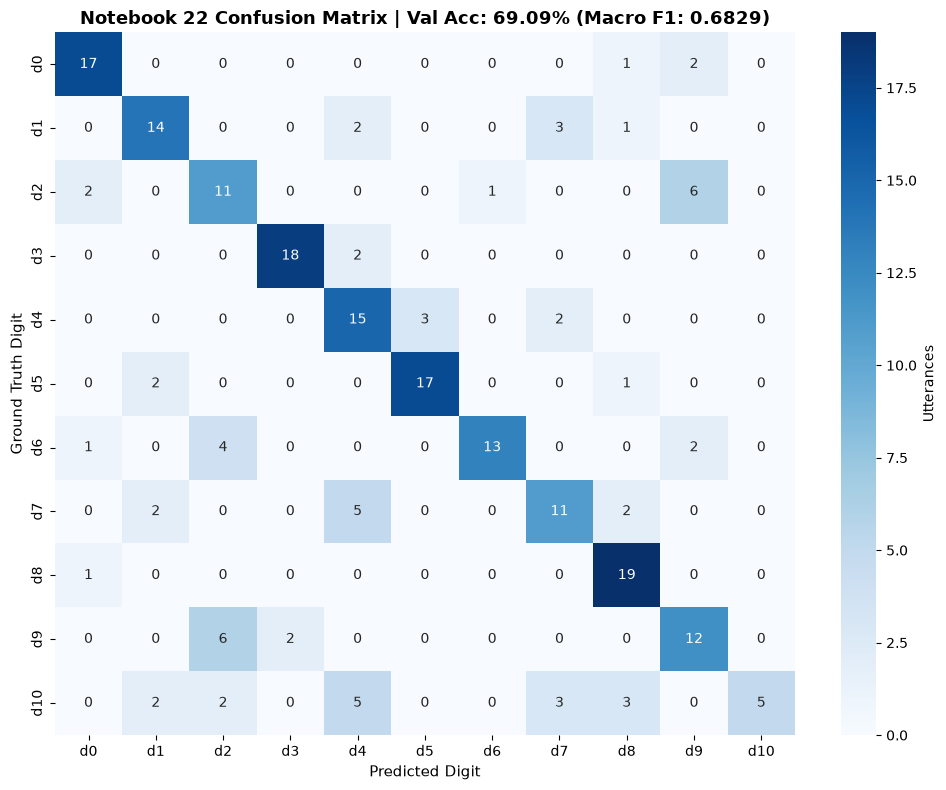

Confusion matrix saved to: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_triwindow_signed_motion_80_20/confusion_matrix_80_20.png
Saved consolidated metrics to: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_triwindow_signed_motion_80_20/metrics_80_20.json
EXPERIMENT 22 INFERENCE & DIAGNOSTICS COMPLETE


In [14]:
# Section 14: Detailed Diagnostics & Quantitative Artifacts Persistence

target_names = [f"{d} ({DIGIT_NAMES[d]})" for d in DIGIT_CLASSES]
report_str = classification_report(y_val, y_pred_final, target_names=target_names, digits=4, zero_division=0)
report_dict = classification_report(y_val, y_pred_final, target_names=DIGIT_CLASSES, output_dict=True, zero_division=0)

print("=" * 80)
print("PER-DIGIT CLASSIFICATION REPORT (SNAPSHOT ENSEMBLE + 4-VIEW TTA)")
print("=" * 80)
print(report_str)

# Per-Speaker Breakdown
df_val["y_true"] = y_val
df_val["y_pred"] = y_pred_final
df_val["correct"] = (df_val["y_true"] == df_val["y_pred"]).astype(int)

speaker_records = []
print("=" * 80)
print("VALIDATION ACCURACY BREAKDOWN BY BASE SPEAKER")
print("=" * 80)
for base_spk in sorted(list(df_val["base_speaker"].unique())):
    grp = df_val[df_val["base_speaker"] == base_spk]
    spk_acc = float(grp["correct"].mean())
    correct_cnt = int(grp["correct"].sum())
    total_cnt = int(len(grp))
    speaker_records.append({
        "base_speaker": base_spk,
        "accuracy": spk_acc,
        "correct": correct_cnt,
        "total": total_cnt
    })
    status = "🌟 High Tier" if spk_acc >= 0.75 else ("Solid Mid Tier" if spk_acc >= 0.65 else "Challenging")
    print(f"  Speaker {base_spk:<6} : {spk_acc*100:6.2f}% ({correct_cnt:2d}/{total_cnt:2d} correct) [{status}]")
print("=" * 80)

# Confusion Matrix Heatmap
cm = confusion_matrix(y_val, y_pred_final)
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=DIGIT_CLASSES, yticklabels=DIGIT_CLASSES,
    cbar_kws={"label": "Utterances"}
)
plt.title(f"Notebook 22 Confusion Matrix | Val Acc: {final_acc*100:.2f}% (Macro F1: {final_f1:.4f})", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Digit", fontsize=11)
plt.ylabel("Ground Truth Digit", fontsize=11)
plt.tight_layout()

cm_path = RESULTS_DIR / "confusion_matrix_80_20.png"
plt.savefig(cm_path, dpi=200)
plt.show()
print(f"Confusion matrix saved to: {cm_path}")

# Quantitative JSON Metrics Persistence
with open(RESULTS_DIR / "classification_report.json", "w") as f:
    json.dump(report_dict, f, indent=2)

with open(RESULTS_DIR / "per_speaker_breakdown.json", "w") as f:
    json.dump(speaker_records, f, indent=2)

metrics_summary = {
    "experiment": "22_efficientnetb0_bigru_triwindow_signed_motion",
    "dataset_mode": DATASET_MODE,
    "seed": SEED,
    "total_validation_utterances": N_val,
    "ablation": {
        "val_accuracy_top1_single_view": float(acc_top1_no_tta),
        "val_accuracy_top1_tta": float(acc_top1_tta),
        "val_accuracy_snapshot_single_view": float(acc_ens_no_tta),
        "val_accuracy_snapshot_tta": float(final_acc)
    },
    "macro_precision": float(final_precision),
    "macro_recall": float(final_recall),
    "macro_f1": float(final_f1),
    "total_correct": int(np.sum(y_pred_final == y_val)),
    "stage1_best_val_acc": float(best_s1_acc),
    "stage2_best_val_acc": float(best_s2_acc),
    "tri_windows": {
        "onset_window": list(ONSET_WINDOW),
        "nucleus_window": list(NUCLEUS_WINDOW),
        "coda_window": list(CODA_WINDOW)
    },
    "per_speaker_breakdown": speaker_records
}

metrics_path = RESULTS_DIR / "metrics_80_20.json"
with open(metrics_path, "w") as f:
    json.dump(metrics_summary, f, indent=2)

df_val[["speaker", "base_speaker", "digit", "digit_id", "y_pred", "correct"]].to_csv(
    RESULTS_DIR / "utterance_predictions_80_20.csv", index=False
)

print(f"Saved consolidated metrics to: {metrics_path}")
print("=" * 80)
print("EXPERIMENT 22 INFERENCE & DIAGNOSTICS COMPLETE")
print("=" * 80)
